In [4]:

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings('ignore')




In [5]:
# Step 2: Read the dataset
df = pd.read_csv("Churn_Modelling.csv")

print("First five records:")
print(df.head())

print("\nDataset Shape:", df.shape)
print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())



First five records:
   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63    


Customer Churn Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


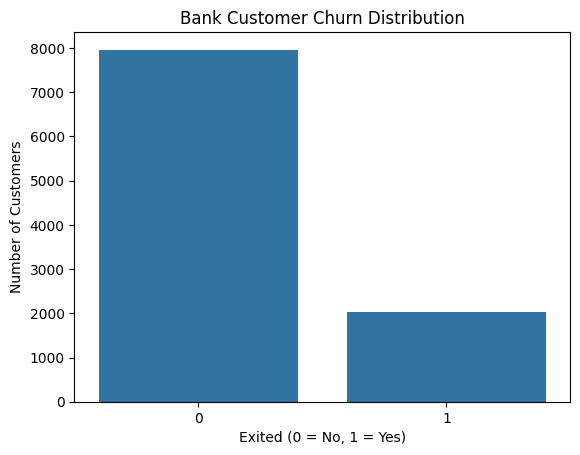


Features Shape: (10000, 10)
Target Shape: (10000,)

Training Data: (8000, 10)
Testing Data: (2000, 10)

========== BASELINE MODEL ==========
Accuracy: 86.5 %

Confusion Matrix:
[[1543   50]
 [ 220  187]]

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.88      0.97      0.92      1593
     Churned       0.79      0.46      0.58       407

    accuracy                           0.86      2000
   macro avg       0.83      0.71      0.75      2000
weighted avg       0.86      0.86      0.85      2000


========== IMPROVED MODEL ==========
Accuracy: 79.1 %

Confusion Matrix:
[[1287  306]
 [ 112  295]]

Classification Report:
              precision    recall  f1-score   support

 Not Churned       0.92      0.81      0.86      1593
     Churned       0.49      0.72      0.59       407

    accuracy                           0.79      2000
   macro avg       0.71      0.77      0.72      2000
weighted avg       0.83      0.79      0.80    

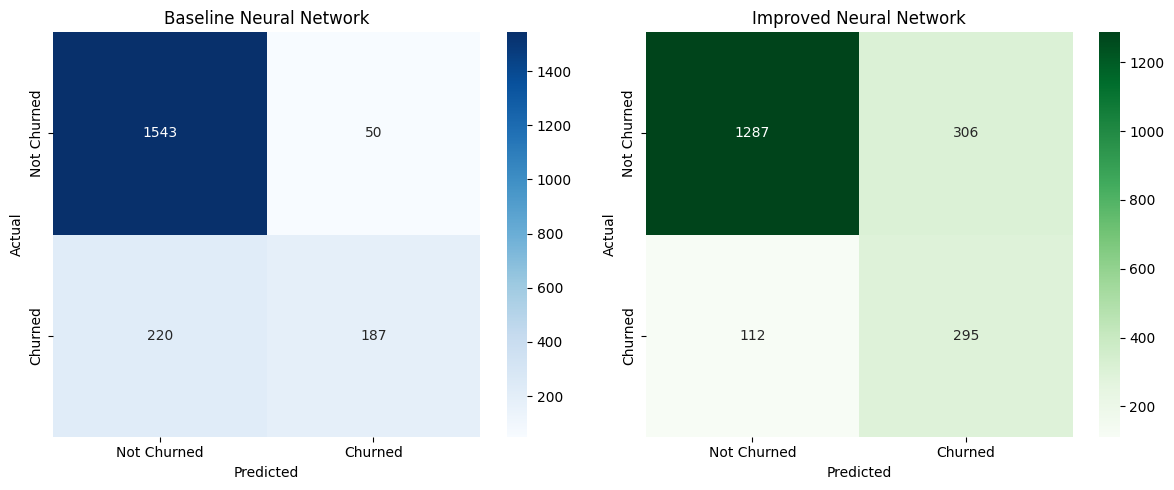


========== MODEL COMPARISON ==========
                  Model  Accuracy (%)
Baseline Neural Network          86.5
Improved Neural Network          79.1


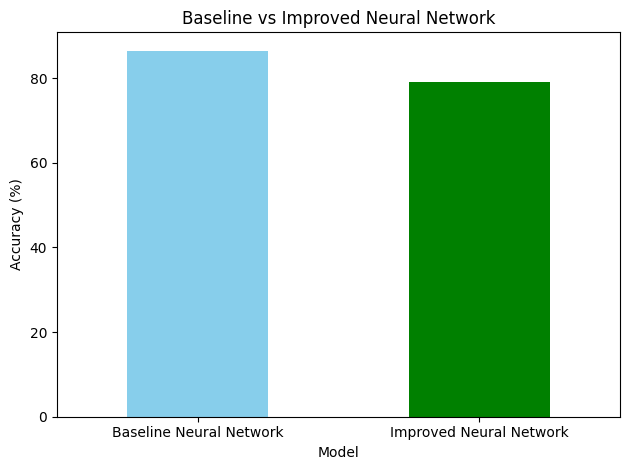


========== CUSTOMER CHURN PREDICTION ==========
Prediction: Customer is likely to stay.


In [6]:

# Step 3: Visualize target distribution
print("\nCustomer Churn Distribution:")
print(df['Exited'].value_counts())

sns.countplot(x='Exited', data=df)
plt.title("Bank Customer Churn Distribution")
plt.xlabel("Exited (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()


# Step 4: Separate features and target
# Remove identifier columns
X = df.drop(
    columns=['RowNumber', 'CustomerId', 'Surname', 'Exited']
)

y = df['Exited']

print("\nFeatures Shape:", X.shape)
print("Target Shape:", y.shape)


# Step 5: Identify numerical and categorical columns
categorical_columns = ['Geography', 'Gender']

numerical_columns = [
    col for col in X.columns
    if col not in categorical_columns
]


# Step 6: Divide dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# Step 7: Normalize and encode the data
# StandardScaler normalizes numerical features.
# OneHotEncoder converts categorical features into numbers.

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_columns)
    ]
)


# Step 8: Build the baseline neural network
baseline_model = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', MLPClassifier(
            hidden_layer_sizes=(16,),
            activation='relu',
            solver='adam',
            max_iter=300,
            early_stopping=True,
            n_iter_no_change=20,
            random_state=42
        ))
    ]
)


# Step 9: Train the baseline model
baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

baseline_accuracy = accuracy_score(
    y_test, baseline_predictions
)

baseline_cm = confusion_matrix(
    y_test, baseline_predictions
)

print("\n========== BASELINE MODEL ==========")
print("Accuracy:", round(baseline_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(baseline_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_predictions,
    target_names=['Not Churned', 'Churned']
))


# Step 10: Improve the model using oversampling
# The dataset contains fewer churned customers.
# Increase minority-class training examples to balance classes.

training_data = pd.concat(
    [X_train, y_train],
    axis=1
)

majority = training_data[
    training_data['Exited'] == 0
]

minority = training_data[
    training_data['Exited'] == 1
]

minority_upsampled = resample(
    minority,
    replace=True,
    n_samples=len(majority),
    random_state=42
)

balanced_data = pd.concat(
    [majority, minority_upsampled]
).sample(frac=1, random_state=42)

X_train_balanced = balanced_data.drop(
    columns=['Exited']
)

y_train_balanced = balanced_data['Exited']


# Step 11: Build improved neural network
improved_model = Pipeline(
    steps=[
        ('preprocessing', preprocessor),
        ('classifier', MLPClassifier(
            hidden_layer_sizes=(32, 16),
            activation='relu',
            solver='adam',
            alpha=0.001,
            learning_rate_init=0.001,
            max_iter=400,
            early_stopping=True,
            validation_fraction=0.15,
            n_iter_no_change=25,
            random_state=42
        ))
    ]
)


# Step 12: Train improved model
improved_model.fit(
    X_train_balanced,
    y_train_balanced
)

improved_predictions = improved_model.predict(X_test)

improved_accuracy = accuracy_score(
    y_test, improved_predictions
)

improved_cm = confusion_matrix(
    y_test, improved_predictions
)

print("\n========== IMPROVED MODEL ==========")
print("Accuracy:", round(improved_accuracy * 100, 2), "%")

print("\nConfusion Matrix:")
print(improved_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    improved_predictions,
    target_names=['Not Churned', 'Churned']
))


# Step 13: Plot confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned'],
    ax=axes[0]
)

axes[0].set_title("Baseline Neural Network")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    improved_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=['Not Churned', 'Churned'],
    yticklabels=['Not Churned', 'Churned'],
    ax=axes[1]
)

axes[1].set_title("Improved Neural Network")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# Step 14: Compare model accuracy
comparison = pd.DataFrame({
    'Model': ['Baseline Neural Network',
              'Improved Neural Network'],
    'Accuracy (%)': [
        baseline_accuracy * 100,
        improved_accuracy * 100
    ]
})

print("\n========== MODEL COMPARISON ==========")
print(comparison.round(2).to_string(index=False))

comparison.plot(
    x='Model',
    y='Accuracy (%)',
    kind='bar',
    legend=False,
    color=['skyblue', 'green']
)

plt.title("Baseline vs Improved Neural Network")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


# Step 15: Predict a sample customer
sample_customer = X_test.iloc[[0]]

prediction = improved_model.predict(sample_customer)[0]

print("\n========== CUSTOMER CHURN PREDICTION ==========")

if prediction == 1:
    print("Prediction: Customer is likely to churn.")
else:
    print("Prediction: Customer is likely to stay.")